In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

In [4]:
print(torch.cuda.is_available())

True


In [5]:
import sys

import matplotlib
import numpy as np
import torch
import torchvision

print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA runtime used by PyTorch:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(3, 3, device="cuda")
    print("CUDA tensor:")
    print(x)
else:
    print("PyTorch is currently running without CUDA.")

Python executable: c:\Users\jimmy\VS_Code_Projects\MyOwnMLProjects\.MyOwnVenv\Scripts\python.exe
NumPy: 2.5.1
Matplotlib: 3.11.0
PyTorch: 2.13.0+cu132
Torchvision: 0.28.0+cu132
CUDA available: True
CUDA runtime used by PyTorch: 13.2
GPU: NVIDIA GeForce RTX 4080 SUPER
CUDA tensor:
tensor([[ 5.8396e-01, -7.0115e-01, -1.1648e+00],
        [ 7.0848e-01,  1.0354e+00,  3.2222e-01],
        [ 8.7520e-01,  1.6940e-04,  9.2403e-01]], device='cuda:0')


CIFAR10 Dataset
* airplane (0)
* automobile (1)
* bird (2)
* cat (3)
* deer (4)
* dog (5)
* frog (6)
* horse (7)
* ship (8)
* truck (9)

Transformations
* Use same compose object or both training and validation for now. No data augmentation yet. Need basics of totensor(). Consider normalize() & resize()...
* Create an instance of the available dataset and load it using torch.utils.data.Dataset class. Will be downloaded locally first time it is run
* Access data in Dataset class using Dataloader

In [2]:
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np

batch_size  = 64
num_workers = 4

transformations = v2.Compose([
    v2.ToImage(), v2.ToDtype(torch.float32, scale=True), v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root='../data', train=True, download=True, transform=transformations)
val_set   = torchvision.datasets.CIFAR10(root='../data', train=False, download=True, transform=transformations)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

training_dataloader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_dataloader      = torch.utils.data.DataLoader(val_set,   batch_size=batch_size, shuffle=True, num_workers=num_workers)

In [9]:
# Check dimensions of single image
cifar_image, label = train_set[0]
print("Image Shape of: ", cifar_image.shape)

Image Shape of:  torch.Size([3, 32, 32])


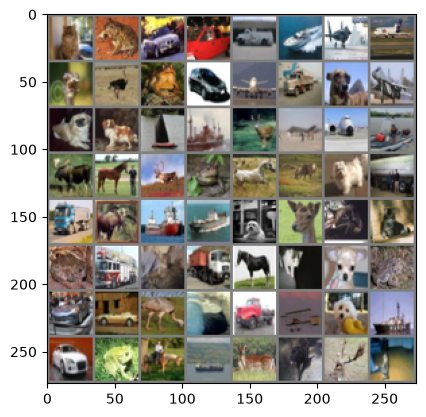

cat   frog  car   car   truck ship  plane plane bird  bird  frog  car   plane truck dog   plane dog   dog   ship  ship  deer  plane plane ship  deer  horse deer  frog  horse deer  dog   truck truck deer  ship  ship  dog   deer  cat   cat   frog  truck cat   truck horse cat   dog   frog  car   car   bird  cat   truck plane dog   ship  car   frog  horse ship  deer  dog   deer  cat  


In [ ]:
def show_image(image):
    """
    Args:
        image: Is of dimensions (C, H, W)

    Notes: 
        - Assumes input image was normalized by: y = (x-0.5)/(0.5)
        - matplotlib.pyplot.imshow() expects inputs of shape (H, W, C)
        and 0-1 for float and 0-255 for int
    """
    image = image / 2 + 0.5     # unnormalize
    numpy_image = image.numpy()
    plt.imshow(np.transpose(numpy_image, (1, 2, 0)))
    plt.show()


# Get random images from next training batch/iter
# Note: DataLoader object is is iterable, but itself not an iterator
image, labels = next(iter(training_dataloader))

# Show images
show_image(torchvision.utils.make_grid(image))
# Print labels
print(' '.join(f'{classes[labels[kk]]:5s}' for kk in range(batch_size)))

In [25]:
import torch.nn as nn
import torch.nn.functional as Functional


class BasicCNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.net = nn.Sequential(
            nn.LazyConv2d(out_channels=8, kernel_size=7, stride=1, padding=3), nn.ReLU(), 
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.LazyConv2d(out_channels=16, kernel_size=5, stride=1, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Flatten(), 
            nn.LazyLinear(out_features=120), nn.ReLU(),
            nn.LazyLinear(out_features=84),  nn.ReLU(), 
            nn.LazyLinear(out_features=10)
        )
    
    def forward(self, input):
        return self.net(input)
    
    def print_layer_summary(self, X_shape):
        X = torch.randn(size=X_shape)
        with torch.no_grad():
            for layer in self.net:
                X = layer(X)
                print(layer.__class__.__name__, "output shape:\t", X.shape)
    

BasicCNNInstance = BasicCNN()
BasicCNNInstance.print_layer_summary((1, *cifar_image.shape))


Conv2d output shape:	 torch.Size([1, 8, 32, 32])
ReLU output shape:	 torch.Size([1, 8, 32, 32])
MaxPool2d output shape:	 torch.Size([1, 8, 16, 16])
Conv2d output shape:	 torch.Size([1, 16, 14, 14])
ReLU output shape:	 torch.Size([1, 16, 14, 14])
MaxPool2d output shape:	 torch.Size([1, 16, 7, 7])
Flatten output shape:	 torch.Size([1, 784])
Linear output shape:	 torch.Size([1, 120])
ReLU output shape:	 torch.Size([1, 120])
Linear output shape:	 torch.Size([1, 84])
ReLU output shape:	 torch.Size([1, 84])
Linear output shape:	 torch.Size([1, 10])


In [26]:
# Choose GPU when CUDA is available; otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)
model = BasicCNN().to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.85, weight_decay=1e-5)

epochs = 10
print_every = 250

for epoch in range(epochs):
    running_loss = 0.0

    for iteration, (images, labels) in enumerate(training_dataloader):
        # Move the current batch from system RAM to GPU VRAM
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        if (iteration + 1) % print_every == 0:
            print(
                f"[Epoch {epoch + 1}, batch {iteration + 1}] "
                f"average loss: {running_loss / print_every:.3f}"
            )
            running_loss = 0.0

print("Finished Training")

Training device: cuda
[Epoch 1, batch 100] average loss: 2.303
[Epoch 1, batch 200] average loss: 2.302
[Epoch 1, batch 300] average loss: 2.298
[Epoch 1, batch 400] average loss: 2.294
[Epoch 1, batch 500] average loss: 2.290
[Epoch 1, batch 600] average loss: 2.278
[Epoch 1, batch 700] average loss: 2.255
[Epoch 2, batch 100] average loss: 2.222
[Epoch 2, batch 200] average loss: 2.197
[Epoch 2, batch 300] average loss: 2.177
[Epoch 2, batch 400] average loss: 2.152
[Epoch 2, batch 500] average loss: 2.132
[Epoch 2, batch 600] average loss: 2.118
[Epoch 2, batch 700] average loss: 2.083
[Epoch 3, batch 100] average loss: 2.025
[Epoch 3, batch 200] average loss: 2.009
[Epoch 3, batch 300] average loss: 1.979
[Epoch 3, batch 400] average loss: 1.967
[Epoch 3, batch 500] average loss: 1.965
[Epoch 3, batch 600] average loss: 1.943
[Epoch 3, batch 700] average loss: 1.941
[Epoch 4, batch 100] average loss: 1.898
[Epoch 4, batch 200] average loss: 1.874
[Epoch 4, batch 300] average loss: 

In [28]:
# Save the Trained model
PATH = './cifar_net.pt'
torch.save(model.state_dict(), PATH)

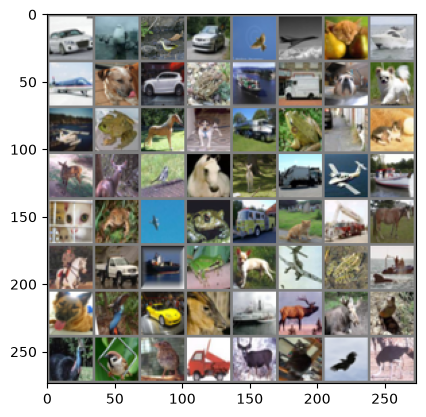

GroundTruth:  car   plane bird  car  


In [36]:
# del iter
dataiter = iter(val_dataloader)
images, labels = next(dataiter)


# Show Some images from validation/test set
show_image(torchvision.utils.make_grid(images))

print(
    "GroundTruth: ",
    " ".join(f"{classes[labels[j]]:5s}" for j in range(4))
)

In [38]:
# Load the model back int
model = BasicCNN()
model.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [40]:
predictions = model(images)
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'for j in range(4)))

Predicted:  ship  ship  frog  ship 


In [43]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in val_dataloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = model(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 52 %


In [47]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in val_dataloader:
        images, labels = data
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 61.5 %
Accuracy for class: car   is 71.6 %
Accuracy for class: bird  is 33.7 %
Accuracy for class: cat   is 29.9 %
Accuracy for class: deer  is 36.9 %
Accuracy for class: dog   is 50.9 %
Accuracy for class: frog  is 70.5 %
Accuracy for class: horse is 60.1 %
Accuracy for class: ship  is 67.2 %
Accuracy for class: truck is 46.1 %
